In [16]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import plotly.colors as colors
pio.templates.default="plotly_white"
data=pd.read_csv("sales.csv",encoding='latin-1')
print(data)

      Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
0          1  CA-2016-152156   11/8/2016  11/11/2016    Second Class   
1          2  CA-2016-152156   11/8/2016  11/11/2016    Second Class   
2          3  CA-2016-138688   6/12/2016   6/16/2016    Second Class   
3          4  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
4          5  US-2015-108966  10/11/2015  10/18/2015  Standard Class   
...      ...             ...         ...         ...             ...   
9989    9990  CA-2014-110422   1/21/2014   1/23/2014    Second Class   
9990    9991  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9991    9992  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9992    9993  CA-2017-121258   2/26/2017    3/3/2017  Standard Class   
9993    9994  CA-2017-119914    5/4/2017    5/9/2017    Second Class   

     Customer ID     Customer Name    Segment        Country             City  \
0       CG-12520       Claire Gute   Consumer  United 

In [17]:
data.head()
data.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [18]:
#Change date and time formate
data['Order Date']= pd.to_datetime(data['Order Date'])
data['Ship Date']=pd.to_datetime(data['Ship Date'])
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [19]:
data .head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [20]:
#Create new columns
data['order month']=data['Order Date'].dt.month
data['Order year']=data['Order Date' ].dt.year
data['Order day of week']=data['Order Date'].dt.dayofweek

In [21]:
data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,order month,Order year,Order day of week
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,11,2016,1
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,11,2016,1
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,6,2016,6
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,10,2015,6
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,10,2015,6


In [26]:
data.to_csv("cleaned_students.csv", index=False)
import os
print(os.getcwd())

C:\Users\Library


    order month        Sales
0             1   94924.8356
1             2   59751.2514
2             3  205005.4888
3             4  137762.1286
4             5  155028.8117
5             6  152718.6793
6             7  147238.0970
7             8  159044.0630
8             9  307649.9457
9            10  200322.9847
10           11  352461.0710
11           12  325293.5035
order month        12.000
Sales          352461.071
dtype: float64
order month        1.0000
Sales          59751.2514
dtype: float64


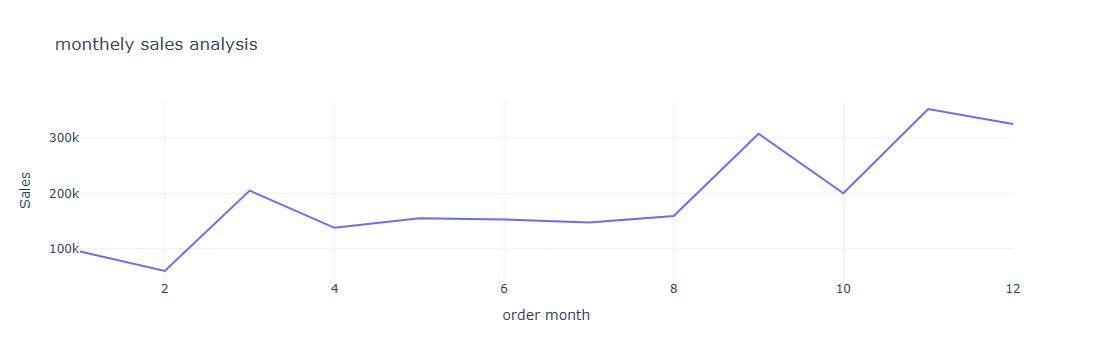

In [23]:
#Sales by Months
sales_by_months = data.groupby('order month')['Sales'].sum().reset_index()
print(sales_by_months)
print(sales_by_months.max())
print(sales_by_months.min())
#Plot graph
fig=px.line(sales_by_months,
            x='order month',
            y='Sales',
            title='monthely sales analysis'
           
    
)
fig.show()


    order month        Sales
0             1   94924.8356
1             2   59751.2514
2             3  205005.4888
3             4  137762.1286
4             5  155028.8117
5             6  152718.6793
6             7  147238.0970
7             8  159044.0630
8             9  307649.9457
9            10  200322.9847
10           11  352461.0710
11           12  325293.5035
order month        12.000
Sales          352461.071
dtype: float64
order month        1.0000
Sales          59751.2514
dtype: float64


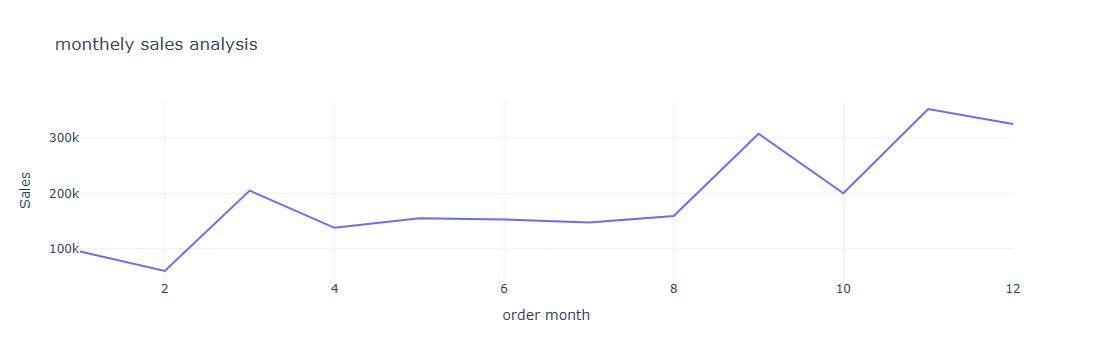

In [23]:
#Sales by Months
sales_by_months = data.groupby('order month')['Sales'].sum().reset_index()
print(sales_by_months)
print(sales_by_months.max())
print(sales_by_months.min())
#Plot graph
fig=px.line(sales_by_months,
            x='order month',
            y='Sales',
            title='monthely sales analysis'
           
    
)
fig.show()


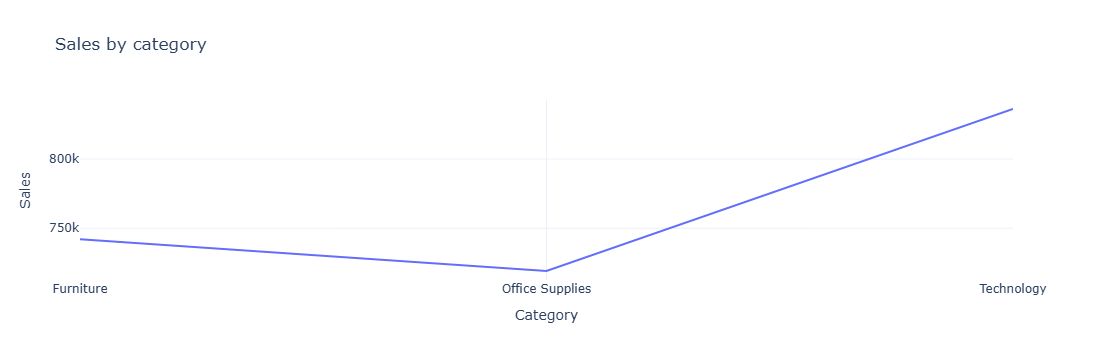

In [10]:
#Sales by category
sales_by_category=data.groupby('Category')['Sales'].sum().reset_index()
sales_by_category
fig=px.line(sales_by_category,
            x='Category',
            y='Sales',
            title='Sales by category')
fig.show()



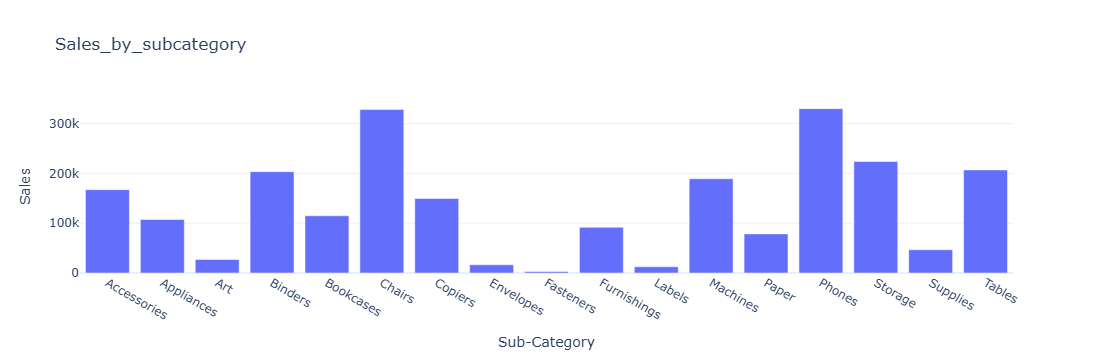

In [11]:
#Sales by Sub-Category
sales_by_subcategory=data.groupby('Sub-Category')['Sales'].sum().reset_index()
sales_by_subcategory
#Plot graph
fig=px.bar(sales_by_subcategory,
           x='Sub-Category',
           y='Sales',
           title='Sales_by_subcategory'
    
)
fig.show()

order month       12.0000
Profit         43369.1919
dtype: float64
order month       1.0000
Profit         9134.4461
dtype: float64


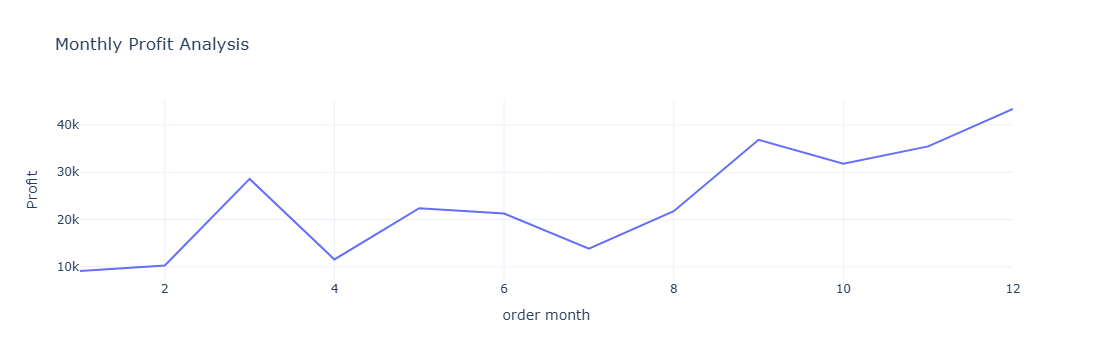

In [22]:
#Profit by Months
Profit_by_months=data.groupby('order month')['Profit'].sum().reset_index()
Profit_by_months
print(Profit_by_months.max())
print(Profit_by_months.min())
#plot graph
fig=px.line(Profit_by_months,x='order month',y='Profit',title='Monthly Profit Analysis')
fig.show()

          Category       Profit
0        Furniture   18451.2728
1  Office Supplies  122490.8008
2       Technology  145454.9481


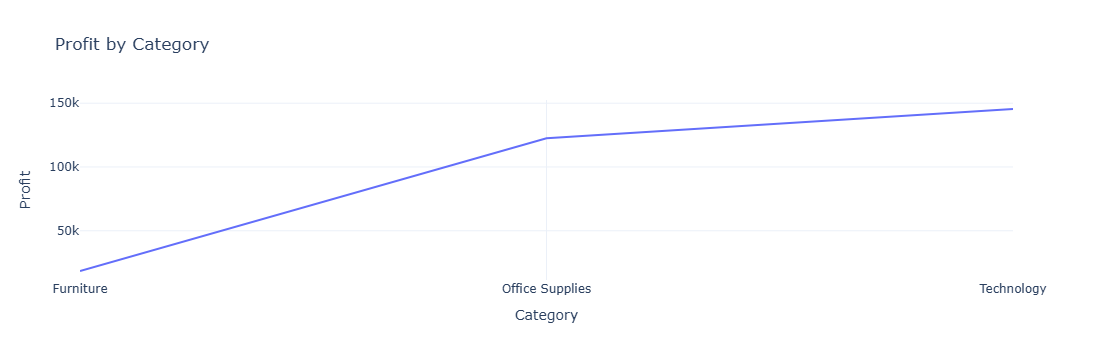

In [13]:
#Profit by Category
Profit_by_category=data.groupby('Category')['Profit'].sum().reset_index()
print(Profit_by_category)
#Plot graph
fig=px.line(Profit_by_category,x='Category',y='Profit',title='Profit by Category')
fig.show()

   Sub-Category      Profit
0   Accessories  41936.6357
1    Appliances  18138.0054
2           Art   6527.7870
3       Binders  30221.7633
4     Bookcases  -3472.5560
5        Chairs  26590.1663
6       Copiers  55617.8249
7     Envelopes   6964.1767
8     Fasteners    949.5182
9   Furnishings  13059.1436
10       Labels   5546.2540
11     Machines   3384.7569
12        Paper  34053.5693
13       Phones  44515.7306
14      Storage  21278.8264
15     Supplies  -1189.0995
16       Tables -17725.4811
Sub-Category        Tables
Profit          55617.8249
dtype: object
Sub-Category    Accessories
Profit          -17725.4811
dtype: object


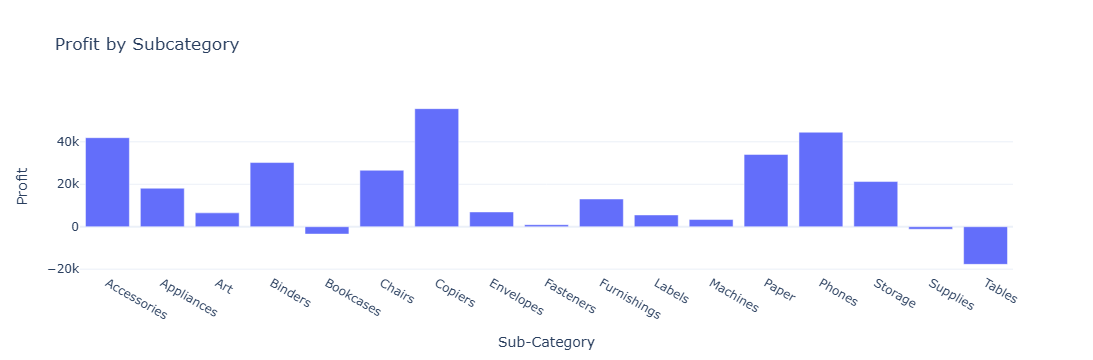

In [7]:
#Profit by Sub-Category
Profit_by_subcategory=data.groupby('Sub-Category')['Profit'].sum().reset_index()
print(Profit_by_subcategory)
print(Profit_by_subcategory.max())
print(Profit_by_subcategory.min())
#plot graph
fig=px.bar(Profit_by_subcategory,x='Sub-Category',y='Profit',title='Profit by Subcategory')
fig.show()

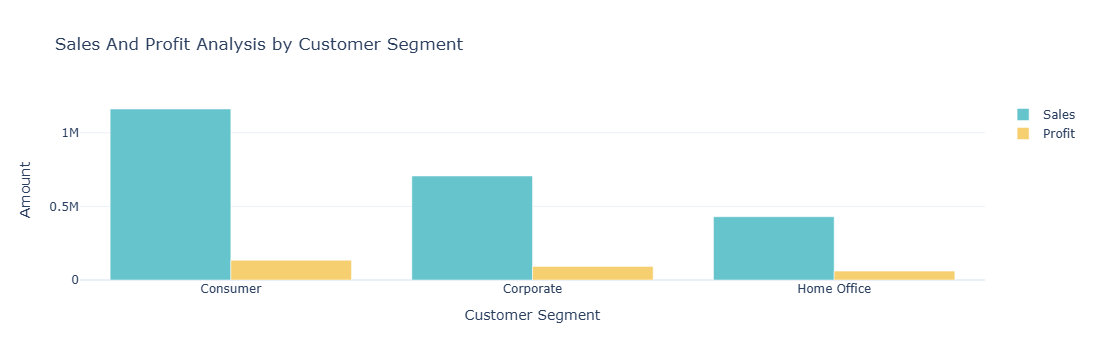

In [8]:
#Sales Profit by Customer Segment
Sales_Profit_by_segment=data.groupby('Segment').agg({'Sales':'sum','Profit':'sum'}).reset_index()
Sales_Profit_by_segment
color_palette=colors.qualitative.Pastel
#Plot graph
fig=go.Figure()
fig.add_trace(go.Bar(x=Sales_Profit_by_segment['Segment'],
                    y=Sales_Profit_by_segment['Sales'],
                    name='Sales',
                    marker_color=color_palette[0]))
fig.add_trace(go.Bar(x=Sales_Profit_by_segment['Segment'],
                    y=Sales_Profit_by_segment['Profit'],
                    name='Profit',
                    marker_color=color_palette[1]))
fig.update_layout(title='Sales And Profit Analysis by Customer Segment',
                 xaxis_title='Customer Segment',
                 yaxis_title='Amount')
fig.show()

       Segment  Sales_to_Profit_ratio
0     Consumer               8.659471
1    Corporate               7.677245
2  Home Office               7.125416


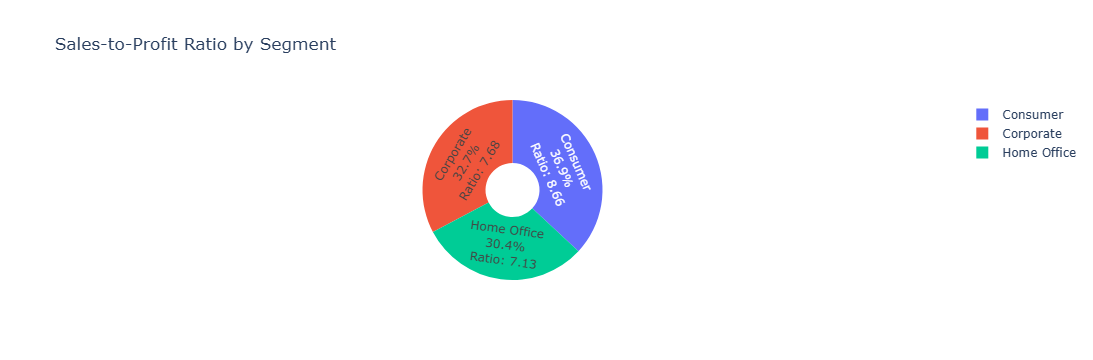

In [9]:
#Sales Profit Ratio
Sales_Profit_by_segment=data.groupby('Segment').agg({'Sales':'sum','Profit':'sum'}).reset_index()
Sales_Profit_by_segment['Sales_to_Profit_ratio']=Sales_Profit_by_segment['Sales']/Sales_Profit_by_segment['Profit']
print(Sales_Profit_by_segment[['Segment','Sales_to_Profit_ratio']])
#Plot graph

# Create Pie Chart
fig = px.pie(
    Sales_Profit_by_segment,
    names='Segment',
    values='Sales_to_Profit_ratio',
    title='Sales-to-Profit Ratio by Segment',
    color='Segment',
    hole=0.3
)

# Display labels and percentages
fig.update_traces(
    textinfo='label+percent+value',
    texttemplate='%{label}<br>%{percent}<br>Ratio: %{value:.2f}',
    textposition='inside'
)

# Customize layout
fig.update_layout(
    template='plotly_white'
)

# Display interactive pie chart
fig.show()